# Causal discovery using fuzzy temporal gradual patterns

Use fuzzy temporal gradual patterns (FTGPs) to generate interpretable hypotheses about which variables precede changes in others. This walkthrough starts with a controlled temporal structural causal model (SCM), then applies the same SO4GP interface to a small Deposium GeoAI weather/vegetation dataset.

We distinguish three kinds of evidence: a synthetic mechanism whose causal direction is known by construction; candidate relationships mined from real observations; and archived cross-validation and benchmark results. A discovered temporal association is a causal hypothesis under assumptions about confounding, temporal order and the selected lags.


## 1. Connect the temporal SCM to an FTGP

Let $\mathbf{X}_t=(X_t^1,\ldots,X_t^p)$ be the observations at time $t$. In the lagged temporal SCM considered here,

$$
X_t^j := f_j\bigl(\mathrm{PA}(X_t^j),U_t^j\bigr),\qquad
\mathrm{PA}(X_t^j)\subseteq\{X_{t-\tau}^{i}:\tau>0\}.
$$

The parent variables occur before their effects; $U_t^j$ denotes an exogenous disturbance. An FTGP supplies a signed, lagged candidate such as

$$
X_{t-\tau}^{+}\rightarrow Y_t^{+}.
$$

The gradual signs describe how values co-vary across compared observations. The lag describes temporal ordering. A negative relationship $X_{t-\tau}^{+}\rightarrow Y_t^{-}$ changes the sign of co-variation while retaining the same source-to-effect arrow. These signs do not require every consecutive observation to increase or decrease.

Temporal precedence and co-variation alone do not identify a causal mechanism. Hidden common causes, seasonality, feedback, omitted lags and contemporaneous mechanisms can change the interpretation. The temporal SCM is an assumed causal framework, not a property proved by the mined pattern. See [Runge et al. (2023), *Causal inference for time series*](https://www.nature.com/articles/s43017-023-00431-y) for the distinction between causal discovery, assumptions and effect estimation.


### Where this approach fits

| Strategy | Main source of information | Examples |
|---|---|---|
| Constraint-based | Conditional-independence tests and orientation rules | PC, PCMCI |
| Score-based | An objective used to compare candidate graph structures | DYNOTEARS |
| Asymmetry-based | Features distinguishing a direction from its reverse | VARLiNGAM |

The proposed FTGP approach is framed here as **temporal asymmetry-based approach**. It mines signed temporal relationships and interprets them within the SCM. It does not use conditional-independence tests or optimize a conventional global causal-graph score.


## 2. Prepare a controlled example

Install this checkout and notebook tools in your environment if needed:

```sh
python -m pip install -e .
python -m pip install jupyterlab ipykernel
python -m jupyterlab examples/causal_discovery.ipynb
```

Run all cells using that environment's kernel. The bundled data lookup supports the repository root or `examples/` as working directory; the notebook needs no Deposium server or credentials.

Generate independent disturbances with a fixed random seed. For rows after the initial condition, the true mechanism is

$$
X_t=U_t^X,\qquad Y_t=1.5X_{t-1}+0.05U_t^Y.
$$

There is one true link, $X_{t-1}\rightarrow Y_t$, and no feedback from $Y$ to $X$. The first $Y$ value supplies the initial condition. Daily sampling makes the one-row lag one day.


In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

import so4gp

print("SO4GP version:", so4gp.__version__)

SO4GP version: 1.1.3


In [2]:
import numpy as np
import pandas as pd

from so4gp.algorithms import TGRAANK

rng = np.random.default_rng(7)
n = 80
x = rng.normal(size=n)
y = np.empty(n)
y[0] = rng.normal()
y[1:] = 1.5 * x[:-1] + 0.05 * rng.normal(size=n - 1)

data = pd.DataFrame(
    {
        "Date": pd.date_range("2024-01-01", periods=n, freq="D").strftime("%Y-%m-%d"),
        "X": x,
        "Y": y,
    }
)

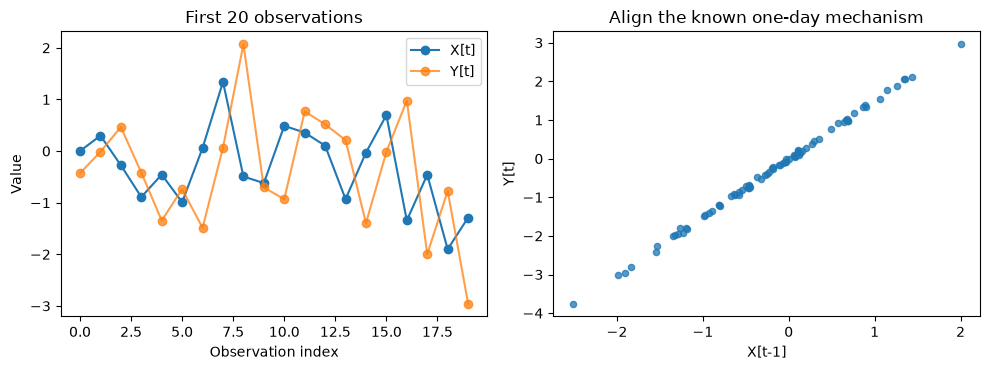

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(np.arange(20), data["X"].iloc[:20], "o-", label="X[t]")
axes[0].plot(np.arange(20), data["Y"].iloc[:20], "o-", label="Y[t]", alpha=0.75)
axes[0].set(xlabel="Observation index", ylabel="Value", title="First 20 observations")
axes[0].legend()
axes[1].scatter(x[:-1], y[1:], s=20, alpha=0.75)
axes[1].set(xlabel="X[t-1]", ylabel="Y[t]", title="Align the known one-day mechanism")
fig.tight_layout()
plt.show()

## 3. Discover candidate directions

`discover_causal_relationships` returns a matrix whose **rows are effects** and **columns are causes**. Thus `scores.loc["Y", "X"]` represents the candidate `X -> Y` direction.

For this example, `max_lag=2` visits the one-row transformation: the current implementation iterates positive shifts below its computed maximum step. For each ordered feature pair, the convenience method keeps the strongest retained pattern support across the searched signs and shifts; the matrix does not itself retain a sign or a specific lag per entry. This method uses its own permissive internal support threshold. Its weights are not causal probabilities, effect sizes or significance levels.


In [4]:
miner = TGRAANK(data, device="cpu")
scores = miner.discover_causal_relationships(max_lag=2)
print(scores.round(3).to_string())

Cause       X      Y
Effect              
X       0.000  0.545
Y       0.986  0.000


,Candidate,True edge in the generating SCM,Dependency weight
0,X -> Y,True,0.986
1,Y -> X,False,0.545


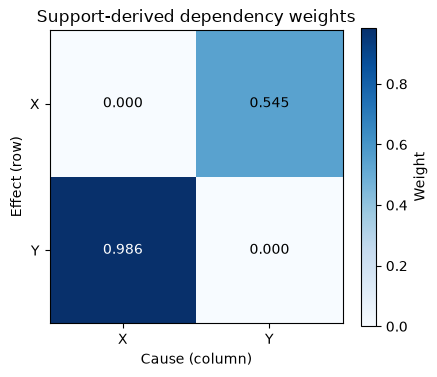

In [5]:
comparison = pd.DataFrame(
    {
        "Candidate": ["X -> Y", "Y -> X"],
        "True edge in the generating SCM": [True, False],
        "Dependency weight": [scores.loc["Y", "X"], scores.loc["X", "Y"]],
    }
)
display(comparison)

fig, ax = plt.subplots(figsize=(4.5, 3.8))
heatmap = ax.imshow(scores.to_numpy(), cmap="Blues", vmin=0)
ax.set_xticks(range(2), scores.columns)
ax.set_yticks(range(2), scores.index)
ax.set(
    xlabel="Cause (column)",
    ylabel="Effect (row)",
    title="Support-derived dependency weights",
)
for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            f"{scores.iloc[i, j]:.3f}",
            ha="center",
            va="center",
            color="white" if scores.iloc[i, j] > 0.7 else "black",
        )
fig.colorbar(heatmap, ax=ax, label="Weight")
fig.tight_layout()
plt.show()

With the fixed seed, the known direction has weight **0.986**, versus **0.545** for the absent reverse link. This is useful directional evidence in the controlled example. The reverse weight also shows why a nonzero matrix entry must not automatically become an accepted causal edge. No classification threshold is selected from this example.


## 4. Inspect gradual signs and estimated lags

Use a separate miner for a specific candidate source. Here `target_col` is **X**, treated as the candidate cause by the causal-reporting interface; it is not the effect variable. The date column occupies position 0, so X is position 1.

The pattern query below retains the one-row transformation using `min_rep=(n-2)/n`. Unlike the matrix convenience method, this query respects the supplied mining support threshold and returns sign/lag metadata. Use `min_sup=0.5` here: the threshold also filters individual GIs before a joint pattern is formed. The expected FTGP is `X+, (Y+) +1.0 days`, corresponding to $X_{t-1}^{+}ightarrow Y_t^{+}$.


In [6]:
def relationship_table(report, columns):
    return pd.DataFrame(
        [
            {
                "Source candidate": columns[item["correlation"][0]],
                "Effect candidate": columns[item["correlation"][1]],
                "Gradual direction": item["direction"],
                "Estimated delay": item["time lag"],
                "Support": item["support"],
            }
            for item in report["Causality"]
        ]
    )


pattern_miner = TGRAANK(data, min_sup=0.5, min_rep=(n - 2) / n, device="cpu")
report = json.loads(
    pattern_miner.discover(
        target_col=data.columns.get_loc("X"),
        transformations="all",
        search_algorithm="apriori",
        compute_causality=True,
    )
)
display(pattern_miner.mining_engine.display_patterns_as_df)
display(relationship_table(report, data.columns))

,Pattern,Support,Confidence
0,"X+, (Y+) +1.0 days",0.986,1


,Source candidate,Effect candidate,Gradual direction,Estimated delay,Support
0,X,Y,+,+1.0 days,0.986


Changing the effect to `-Y` creates a negative gradual relationship while preserving the known temporal arrow. The next result should report direction `-` with the same one-day delay. Direction `-` in this metadata means opposite gradual signs; it does not mean `Y -> X`.


In [7]:
negative_data = data.assign(Y=-data["Y"])
negative_miner = TGRAANK(negative_data, min_sup=0.5, min_rep=(n - 2) / n, device="cpu")
negative_report = json.loads(
    negative_miner.discover(
        target_col=negative_data.columns.get_loc("X"),
        transformations="all",
        search_algorithm="apriori",
        compute_causality=True,
    )
)
display(relationship_table(negative_report, negative_data.columns))

,Source candidate,Effect candidate,Gradual direction,Estimated delay,Support
0,X,Y,-,+1.0 days,0.986


## 5. Apply the interface to your own observations

Keep one date column and numerical features, resolve missing values, sort by date, and rerun the matrix call. For example:

```python
raw = pd.read_csv("my_timeseries.csv")
raw["Date"] = pd.to_datetime(raw["Date"])
data = raw.sort_values("Date")[["Date", "temperature", "flow"]].reset_index(drop=True)
miner = TGRAANK(data, device="cpu")
scores = miner.discover_causal_relationships(max_lag=2)
print(scores.round(3))
```

Choose a lag search appropriate to the sampling cadence and plausible mechanisms. Row shifts only represent equal elapsed durations on regularly sampled data. With more variables, the returned matrix can contain multiple candidate directions and feedback hypotheses; it is not guaranteed to be an identified causal graph.


## 6. A real-life example: Deposium GeoAI at Fos-sur-Mer

Deposium GeoAI joins satellite vegetation observations (`ndvi_mean`) to ERA5 weather variables for environmental analysis. This notebook bundles **48 actual Fos-sur-Mer observations from 2021–2024**, restricted to date, solar radiation and NDVI. The small extract and its hash-linked provenance make the example portable; no live provider or server is called.

The inputs come from the released [ERA5 holdout handoff](https://github.com/theseedship/deposium_geoai/releases/tag/era5-holdout-handoff-2026-09-19) and [satellite NDVI handoff](https://github.com/theseedship/deposium_geoai/releases/tag/b3-ndvi-verification-2026-09-05). The prepared source Parquet has SHA-256 `1d1bba9cd2125fe51e7665f4d2e382c127b12b5ea831ac8dd7c9bd3ae3f21d39`. Its nearest-date alignment was performed separately by period, and all retained source matches were on the same day.

We split **2021–2022** from **2023–2024 before temporal mining**, following the historical study's period boundary. These are new illustrative candidate-matrix runs using this checkout. The archived validation campaign below used six climate variables and three pilots with a separate count-based scorer; its metrics do not describe these two-feature matrices.


In [8]:
repo_root = next(
    (
        path
        for path in (Path.cwd(), Path.cwd().parent)
        if (path / "examples/datasets/deposium_fos_sur_mer.csv").is_file()
    ),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Run from the repository root or examples/ directory.")
dataset_dir = repo_root / "examples/datasets"
provenance = json.loads(
    (dataset_dir / "deposium_validation.json").read_text(encoding="utf-8")
)
csv_path = dataset_dir / "deposium_fos_sur_mer.csv"
assert (
    hashlib.sha256(csv_path.read_bytes()).hexdigest() == provenance["snapshot_sha256"]
)
deposium_data = pd.read_csv(csv_path)
deposium_dates = pd.to_datetime(deposium_data["Date"])
print(
    f"Fos-sur-Mer: {len(deposium_data)} observations, "
    f"{deposium_dates.min():%Y-%m-%d} to {deposium_dates.max():%Y-%m-%d}"
)
display(deposium_data.head())

Fos-sur-Mer: 48 observations, 2021-01-24 to 2024-12-29


,Date,solar_radiation,ndvi_mean
0,2021-01-24,110.995370,0.3159
1,2021-02-11,141.666667,0.2966
2,2021-03-30,245.486111,0.2686
3,2021-04-02,259.143519,0.2790
4,2021-05-12,324.652778,0.3214


In [9]:
real_rows = []
for period, selected in (
    ("2021-2022", deposium_dates.dt.year <= 2022),
    ("2023-2024", deposium_dates.dt.year >= 2023),
):
    panel = deposium_data.loc[selected].reset_index(drop=True)
    gaps = pd.to_datetime(panel["Date"]).diff().dt.days.dropna()
    real_miner = TGRAANK(panel, device="cpu")
    real_scores = real_miner.discover_causal_relationships(max_lag=2)
    real_rows.append(
        {
            "Period": period,
            "Observations": len(panel),
            "Min gap (days)": int(gaps.min()),
            "Max gap (days)": int(gaps.max()),
            "Solar -> NDVI": real_scores.loc["ndvi_mean", "solar_radiation"],
            "NDVI -> solar": real_scores.loc["solar_radiation", "ndvi_mean"],
        }
    )
real_comparison = pd.DataFrame(real_rows)
display(real_comparison.round(3))

,Period,Observations,Min gap (days),Max gap (days),Solar -> NDVI,NDVI -> solar
0,2021-2022,24,3,50,0.680,0.640
1,2023-2024,24,15,57,0.581,0.506


Read the gap ranges before interpreting these weights. The observations are sparse: a one-row shift is not a fixed one-day weather-to-vegetation response. The candidate matrices describe temporal gradual associations in each period. Seasonality and other common drivers remain possible explanations; no causal ground-truth graph is supplied for this site.

### Preserve the tests and cross-validation already performed

The [archived held-out method and results](https://github.com/theseedship/deposium_geoai/blob/44619b95ad8cfeab64f66fa654d5e40c1a0a3120/docs/research/offline-heldout-validation.md) document five spatial folds over **14 eligible Q3 zones**, with overlapping footprints grouped, and a separate three-pilot temporal study. Candidate selection used donors only; temporal selection used 2021–2022 and evaluation used 2023–2024, with periods split before shifting. Support is `J/N` and conditional confidence is `J/A`, from pooled within-zone pair counts.

The original confidence bar was **0.70**. The later **0.50** run was chosen after inspecting results and is an exploratory sensitivity analysis. Its two passing spatial entries are inverse signs of one solar-radiation/NDVI association, not independent discoveries. At support ≥0.50, confidence ≥0.50 is redundant. No result below is a causal probability or a forecast-accuracy measurement.


In [10]:
validation_rows = []
for record in provenance["archived_validation"]:
    validation_rows.append(
        {
            "Confidence bar": record["Confidence threshold"],
            "Run": record["Status"],
            "Spatial candidates passing >=4/5 folds": (
                f"{record['Spatial passing at least 4/5 folds']}/"
                f"{record['Spatial candidates']}"
            ),
            "Temporal passes": (
                f"{record['Temporal passes']}/{record['Temporal candidates']}"
            ),
        }
    )
display(pd.DataFrame(validation_rows))

,Confidence bar,Run,Spatial candidates passing >=4/5 folds,Temporal passes
0,0.7,Original,0/10,6/52
1,0.5,Post hoc sensitivity,2/10,40/52


Two additional archived checks answer different questions:

- The [historical Q3 recurrence study](https://github.com/theseedship/deposium_geoai/blob/44619b95ad8cfeab64f66fa654d5e40c1a0a3120/docs/demo/o3-q3-cross-zone-validation-mesh-rustfs-2026-06-27.md) retained **30 GRAANK patterns and 149 TGrad patterns** over 14 zones and five folds. Recurrence is distinct from the held-out observation-count evaluation above.
- The [14 October integration readback](https://github.com/theseedship/deposium_geoai/blob/44619b95ad8cfeab64f66fa654d5e40c1a0a3120/docs/demo/geoai-post-merge-readback-2026-10-14.md) records **3,250 passing tests, four skipped, and 88.50% coverage** for #290. These are archived software checks, not a fresh full-suite run or causal-validation accuracy.

The bundled `deposium_validation.json` records source identities and hashes of the four archived result files. We verified the copied counts against those files without rerunning the historical campaign. Sparse sampling and geographically dependent pilots limit transfer; neither the real-data matrix nor the CV evidence establishes a weather intervention effect on vegetation.


## 7. Archived CausalRivers benchmark

The table below reads the repository's [saved benchmark export](../benchmarks/benchmarking-results.json). Its metric is **mean per graph AUROC**, excluding autoregressive diagonal entries. It is distinct from pooled AUROC, the controlled example and Deposium's validation counts.

The [benchmark report](../benchmarks/benchmarking-results.md) supplies the scoring paths and published comparator provenance. These results were not rerun for this notebook. Preprocessing and search budgets have not been established as identical across methods, so this is an archived descriptive comparison.


In [11]:
benchmark = json.loads(
    (repo_root / "benchmarks/benchmarking-results.json").read_text(encoding="utf-8")
)
benchmark_df = pd.DataFrame(
    [
        {
            "Graph set": entry["graph_set"],
            **entry["saved_notebook_mean_per_graph_auroc"],
        }
        for entry in benchmark["causalrivers"]
    ]
).set_index("Graph set")
display(benchmark_df)

,TGRAANK,PCMCI,PC,VARLiNGAM,DYNOTEARS
Graph set,,,,,
Close 3,0.677891,0.639,0.501,0.786,0.501
Close 5,0.654067,0.617,0.514,0.773,0.499
Root cause 3,0.700800,0.696,0.501,0.772,0.503
Root cause 5,0.704923,0.737,0.517,0.769,0.564
Random+1 3,0.828725,0.831,0.498,0.840,0.519
Random+1 5,0.734016,0.735,0.513,0.788,0.608
Confounder 3,0.651331,0.663,0.490,0.675,0.525
Confounder 5,0.586420,0.640,0.514,0.698,0.532
Random 3,0.669843,0.655,0.501,0.787,0.503


PC has no reported Disjoint-10 value. Random+1-5 retains the saved TGRAANK value **0.734016**; the restored original scoring artifact gives **0.734275**, as documented in the benchmark report. The table preserves the saved comparison rather than silently mixing artifact versions.

## 8. Interpret the resulting structure

FTGP mining supplies temporally ordered, signed associations that can guide causal hypotheses. The controlled SCM makes direction checkable; the Deposium example shows why real observations require careful lag interpretation and held-out evidence; the CausalRivers results evaluate a separate graph-recovery task.

To use a discovered structure for intervention or counterfactual reasoning, first justify the causal assumptions, address confounding and identify or fit the relevant structural mechanisms. A dependency matrix alone does not estimate those effects.
